# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional
expression notebook follows signatures directly, per §6.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus). Per the **derive-don't-inherit**
mandate we do **not** inherit that pair: we score a candidate EMT-TF panel — the canonical
Snail/Zeb/Twist factors **plus the mesenchymal/neural-crest FOXC and PRRX families** (per the
Kürten lesson) — along *this* trajectory, gate on detectable expression, and let the data choose
the most end-specific factor at each end. VIM is deliberately excluded — vimentin is a
mesenchymal *marker*, not a transcription factor. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(float(t.min()),2), '->', round(float(t.max()),2))

cells: 6322 | pseudotime range 0.0 -> 10.93


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root) vs
late (terminus) pseudotime tercile, and Spearman correlation with pseudotime. Most negative
correlation (sufficiently expressed) marks the root end; most positive marks the terminus.
Factors below a 3% expression floor are too sparse to overlay.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(float(expr.mean()),3), round(float(x[early].mean()),3),
                 round(float(x[late].mean()),3), round(float(rho),3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.287       0.260      0.201    -0.014    EARLY(root)
TWIST2      0.003       0.001      0.001    -0.004 LATE(terminus)
 PRRX1      0.145       0.070      0.077     0.012 LATE(terminus)
 PRRX2      0.113       0.090      0.079     0.016    EARLY(root)
TWIST1      0.155       0.056      0.050     0.021    EARLY(root)
  ZEB1      0.011       0.004      0.008     0.027 LATE(terminus)
 SNAI1      0.098       0.026      0.030     0.028 LATE(terminus)
  ZEB2      0.024       0.011      0.023     0.038 LATE(terminus)
 FOXC2      0.167       0.079      0.101     0.041 LATE(terminus)
 SNAI2      0.156       0.059      0.155     0.076 LATE(terminus)

derived pair: FOXC1 (early/root) <-> SNAI2 (late/terminus)


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`. Categorical overlay of
thresholded expressers on a grey manifold (not a continuous single-gene colormap). The abundant
marker is drawn first so the sparser one reads on top; each factor is thresholded at the upper
quartile of expression among its expressing cells, so only the strongest expressers show and the
early (blue) / late (red) regions separate.

overlay thresholds (upper quartile among expressers): {'FOXC1': 1.123, 'SNAI2': 1.04} | cells shown: {'FOXC1': 454, 'SNAI2': 247}
FOXC1: 28.7% expressing; 454 shown (upper quartile), mean pseudotime of shown cells = 0.39 (all cells = 0.47)
SNAI2: 15.6% expressing; 247 shown (upper quartile), mean pseudotime of shown cells = 0.64 (all cells = 0.47)
shown-cell pseudotime separation (FOXC1 vs SNAI2) = 0.25
saved expression.pdf


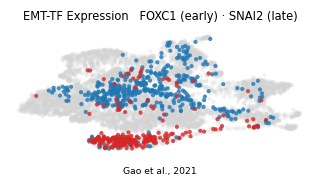

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Gao et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean())
print(f'shown-cell pseudotime separation ({early_tf} vs {late_tf}) = {sep:.2f}')
print('saved expression.pdf')